# 06 – Test Değerlendirmesi, Açıklanabilir Yapay Zeka ve Karşılaştırma

Bu notebook şunları içerir:
- 04 ve 05'te validation ile seçilen modellerin **test verisinde bir kez** değerlendirilmesi ve overfitting'in son kontrolü
- Açıklanabilir yapay zeka yöntemi olarak SHAP ile en iyi modelin kararlarının açıklanması
- Modellerin karşılaştırma tablosu, grafikleri, avantaj ve dezavantajları
- Sonuç ve öneriler

Modeller yeniden eğitilmez, `outputs/models/` klasöründeki kayıtlı en iyi modeller yüklenir. Test verisi yalnızca bu notebook'ta kullanılır ve sonuçlara bakılarak modellerde değişiklik yapılmaz.

Girdi: `outputs/X_test.csv`, `y_test.csv`, `outputs/models/best_*.pkl`, `en_iyi_parametreler.csv`
Çıktı: `outputs/test_sonuclari.csv`, `tahminler.csv`, `shap_onem.csv` ve grafikler

## 1. Kurulum

SHAP kurulu değilse aşağıdaki satırın başındaki `#` işaretini kaldırıp bir kez çalıştırın, ardından kernel'i yeniden başlatın. XGBoost modelini yüklemek için `xgboost` paketinin de kurulu olması gerekir (05'te kuruldu).

In [3]:
#%pip install shap

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

os.makedirs("outputs/figures", exist_ok=True)

def grafik_kaydet(ad):
    # O anki grafiği rapor için PNG olarak kaydeder
    plt.savefig(f"outputs/figures/{ad}.png", dpi=150, bbox_inches="tight")

## 2. Test verisi ve modellerin yüklenmesi

In [4]:
X_test = pd.read_csv("outputs/X_test.csv")
y_test = pd.read_csv("outputs/y_test.csv").squeeze()
X_train = pd.read_csv("outputs/X_train.csv")      # sadece SHAP için arka plan verisi olarak gerekebilir

model_adlari = {"lr": "Logistic Regression", "knn": "KNN", "svm": "SVM",
                "rf": "Random Forest", "xgb": "XGBoost"}
modeller = {kod: joblib.load(f"outputs/models/best_{kod}.pkl") for kod in model_adlari}

en_iyi_param = pd.read_csv("outputs/en_iyi_parametreler.csv").set_index("model")

print("Test:", X_test.shape)
print("Yüklenen modeller:", list(modeller))

Test: (1155, 31)
Yüklenen modeller: ['lr', 'knn', 'svm', 'rf', 'xgb']


## 3. Test değerlendirmesi

Her model için test verisinde tahmin yapılır. İki noktaya dikkat edilir:
- **XGBoost** 0/1 etiketleriyle eğitildiği için (phishing = 1) tahminleri tekrar -1/1'e çevrilir.
- ROC-AUC için her modelden **phishing olma skoru** alınır: olasılık veren modellerde phishing olasılığı, SVM'de ise karar fonksiyonu değeri (SVM varsayılan ayarda olasılık üretmez).

In [5]:
def tahmin_et(kod, model, X):
    # Tahminleri -1/1 olarak ve phishing olma skorunu döndürür
    if kod == "xgb":
        tahmin = np.where(model.predict(X) == 1, -1, 1)          # 1 (phishing) → -1, 0 (normal) → 1
        skor = model.predict_proba(X)[:, 1]                       # phishing olasılığı
    else:
        tahmin = model.predict(X)
        if hasattr(model, "predict_proba"):
            skor = model.predict_proba(X)[:, list(model.classes_).index(-1)]
        else:
            skor = -model.decision_function(X)                    # SVM: pozitif değer normal sınıfı gösterir, işaret çevrilir
    return tahmin, skor

tahminler = pd.DataFrame({"gercek": y_test})
satirlar = []
for kod, model in modeller.items():
    tahmin, skor = tahmin_et(kod, model, X_test)
    tahminler[f"{kod}_tahmin"] = tahmin
    tahminler[f"{kod}_skor"] = skor
    satirlar.append({
        "model": model_adlari[kod],
        "f1": f1_score(y_test, tahmin, pos_label=-1),
        "recall": recall_score(y_test, tahmin, pos_label=-1),
        "precision": precision_score(y_test, tahmin, pos_label=-1),
        "accuracy": accuracy_score(y_test, tahmin),
        "roc_auc": roc_auc_score(y_test == -1, skor),
    })

test_sonuc = pd.DataFrame(satirlar).round(4)
test_sonuc.to_csv("outputs/test_sonuclari.csv", index=False)
tahminler.to_csv("outputs/tahminler.csv", index=False)

test_sonuc.sort_values("f1", ascending=False)

,model,f1,recall,precision,accuracy,roc_auc
3,Random Forest,0.9646,0.9630,0.9663,0.9636,0.9944
2,SVM,0.9631,0.9647,0.9615,0.9619,0.9889
4,XGBoost,0.9589,0.9597,0.9581,0.9576,0.9941
1,KNN,0.9480,0.9496,0.9464,0.9463,0.9916
0,Logistic Regression,0.9350,0.9311,0.9390,0.9333,0.9780


### 3.1 Validation ve test karşılaştırması (overfitting son kontrolü)

Model seçimi validation skorlarıyla yapıldı. Test skorları validation skorlarına yakınsa modeller daha önce görmedikleri veride de aynı başarıyı gösteriyor, yani genelleme yapabiliyor demektir. Test skoru belirgin şekilde düşükse validation'a aşırı uyum (overfitting) olmuştur.

In [6]:
karsilastirma = pd.DataFrame({
    "model": [model_adlari[k] for k in modeller],
    "train_f1": [en_iyi_param.loc[k, "train_f1"] for k in modeller],
    "validation_f1": [en_iyi_param.loc[k, "val_f1"] for k in modeller],
    "test_f1": test_sonuc["f1"].values,
})
karsilastirma["val_test_farki"] = (karsilastirma["validation_f1"] - karsilastirma["test_f1"]).round(4)
karsilastirma["validation_sirasi"] = karsilastirma["validation_f1"].rank(ascending=False).astype(int)
karsilastirma["test_sirasi"] = karsilastirma["test_f1"].rank(ascending=False).astype(int)
karsilastirma.to_csv("outputs/train_val_test_karsilastirma.csv", index=False)
karsilastirma

,model,train_f1,validation_f1,test_f1,val_test_farki,validation_sirasi,test_sirasi
0,Logistic Regression,0.9288,0.9286,0.9350,-0.0064,5,5
1,KNN,1.0000,0.9494,0.9480,0.0014,4,4
2,SVM,0.9822,0.9548,0.9631,-0.0083,3,2
3,Random Forest,1.0000,0.9610,0.9646,-0.0036,1,1
4,XGBoost,0.9956,0.9605,0.9589,0.0016,2,3


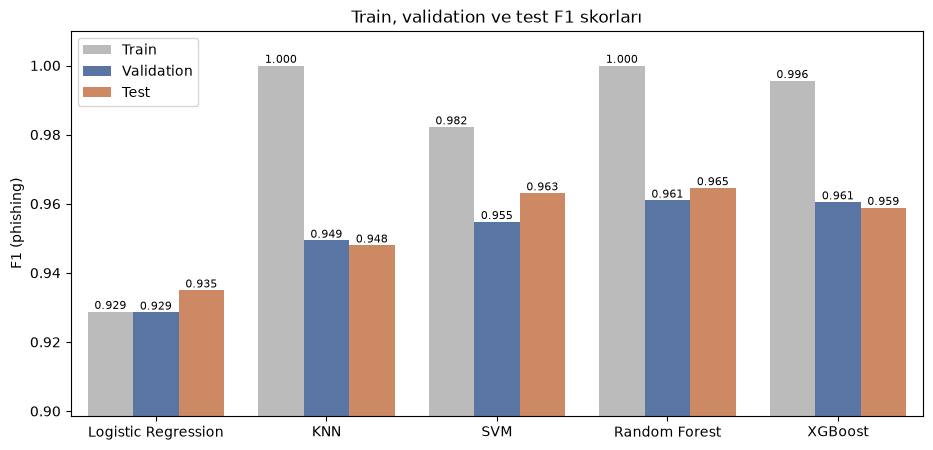

In [7]:
grafik = karsilastirma.melt(id_vars="model", value_vars=["train_f1", "validation_f1", "test_f1"],
                            var_name="kume", value_name="f1")
grafik["kume"] = grafik["kume"].map({"train_f1": "Train", "validation_f1": "Validation", "test_f1": "Test"})

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=grafik, x="model", y="f1", hue="kume", palette=["#bbbbbb", "#4c72b0", "#dd8452"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_ylim(grafik["f1"].min() - 0.03, 1.01)   # farklar görünsün diye eksen 0'dan başlamıyor
ax.set_xlabel("")
ax.set_ylabel("F1 (phishing)")
ax.set_title("Train, validation ve test F1 skorları")
ax.legend(title="")
grafik_kaydet("train_val_test_f1")
plt.show()

### 3.2 Confusion matrix

Satırlar gerçek sınıfı, sütunlar tahmini gösterir. Phishing tespitinde en kritik hata **kaçırılan phishing siteleri**dir (gerçekte phishing olup normal tahmin edilenler), çünkü kullanıcı bu sitelere güvenip bilgilerini girebilir.

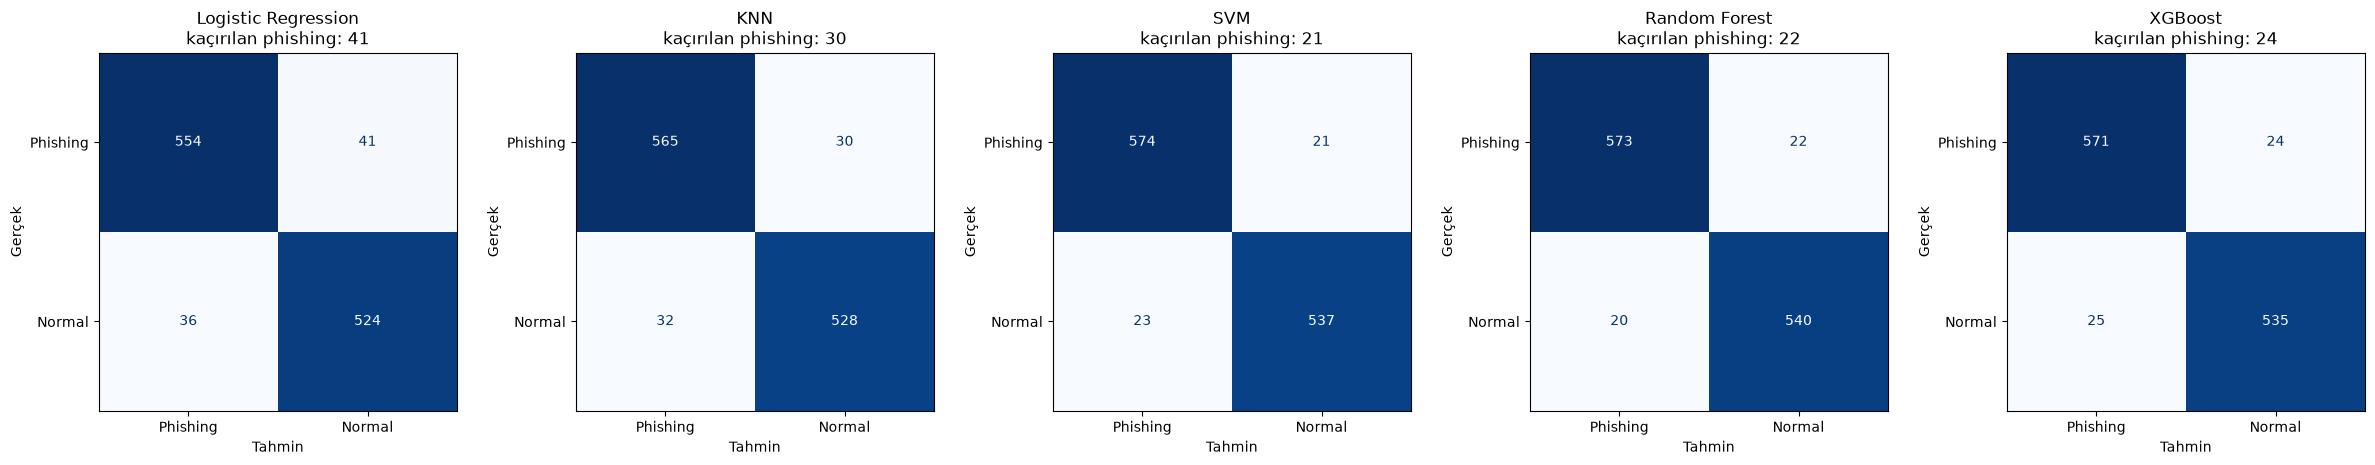

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, kod in zip(axes, modeller):
    cm = confusion_matrix(y_test, tahminler[f"{kod}_tahmin"], labels=[-1, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Phishing", "Normal"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{model_adlari[kod]}\nkaçırılan phishing: {cm[0, 1]}")
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
plt.tight_layout()
grafik_kaydet("confusion_matrix")
plt.show()

In [9]:
# Her model için sınıf bazında precision, recall ve F1
for kod in modeller:
    print(f"===== {model_adlari[kod]} =====")
    print(classification_report(y_test, tahminler[f"{kod}_tahmin"], labels=[-1, 1],
                                target_names=["Phishing", "Normal"], digits=4))

===== Logistic Regression =====
              precision    recall  f1-score   support

    Phishing     0.9390    0.9311    0.9350       595
      Normal     0.9274    0.9357    0.9316       560

    accuracy                         0.9333      1155
   macro avg     0.9332    0.9334    0.9333      1155
weighted avg     0.9334    0.9333    0.9333      1155

===== KNN =====
              precision    recall  f1-score   support

    Phishing     0.9464    0.9496    0.9480       595
      Normal     0.9462    0.9429    0.9445       560

    accuracy                         0.9463      1155
   macro avg     0.9463    0.9462    0.9463      1155
weighted avg     0.9463    0.9463    0.9463      1155

===== SVM =====
              precision    recall  f1-score   support

    Phishing     0.9615    0.9647    0.9631       595
      Normal     0.9624    0.9589    0.9606       560

    accuracy                         0.9619      1155
   macro avg     0.9619    0.9618    0.9619      1155
weighted a

### 3.3 ROC eğrileri

Farklı karar eşiklerinde doğru tespit edilen phishing oranının (TPR) yanlış alarm oranına (FPR) göre değişimi. Eğri sol üst köşeye ne kadar yakınsa ve eğrinin altındaki alan (AUC) 1'e ne kadar yakınsa model o kadar iyidir.

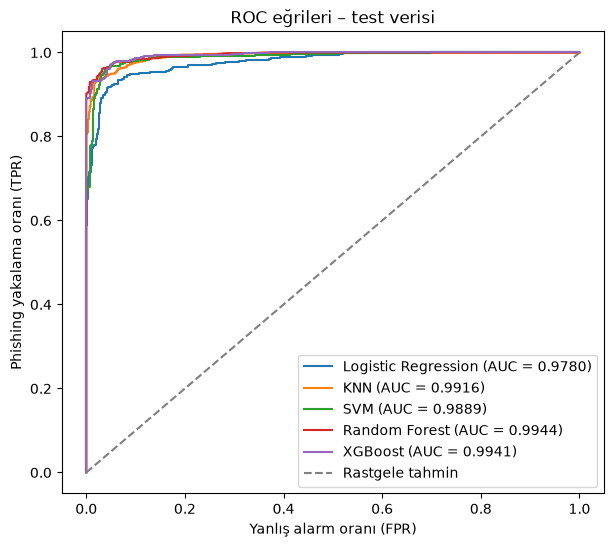

In [10]:
plt.figure(figsize=(7, 6))
for kod in modeller:
    fpr, tpr, _ = roc_curve(y_test == -1, tahminler[f"{kod}_skor"])
    auc = test_sonuc.loc[test_sonuc["model"] == model_adlari[kod], "roc_auc"].iloc[0]
    plt.plot(fpr, tpr, label=f"{model_adlari[kod]} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Rastgele tahmin")
plt.xlabel("Yanlış alarm oranı (FPR)")
plt.ylabel("Phishing yakalama oranı (TPR)")
plt.title("ROC eğrileri – test verisi")
plt.legend(loc="lower right")
grafik_kaydet("roc_egrileri")
plt.show()

## 4. Açıklanabilir yapay zeka (SHAP)

**SHAP (SHapley Additive exPlanations)**, oyun teorisindeki Shapley değerlerine dayanır. Bir tahmini, her özelliğin o tahmine yaptığı katkıların toplamı olarak açıklar:
- **Global açıklama:** Model genel olarak hangi özelliklere dayanarak karar veriyor?
- **Yerel açıklama:** Belirli bir site neden phishing olarak tahmin edildi?

Pozitif SHAP değeri tahmini **phishing** yönüne, negatif değer **normal** yönüne iter.

SHAP, validation F1'e göre en iyi modele uygulanır. Ağaç tabanlı modellerde hızlı ve kesin hesaplama yapan `TreeExplainer` kullanılır. Diğer modeller için modelden bağımsız bir yöntem (permutation) kullanılır, bu yöntem daha yavaştır.

Açıklamalar test verisi üzerinde hesaplanır. Bu bir değerlendirme ya da ayar adımı değildir, modelde değişiklik yapılmaz.

In [11]:
en_iyi_kod = en_iyi_param["val_f1"].idxmax()        # seçim validation'a göre
en_iyi_model = modeller[en_iyi_kod]
print("Validation F1'e göre en iyi model:", model_adlari[en_iyi_kod])

if en_iyi_kod in ("rf", "xgb"):
    explainer = shap.TreeExplainer(en_iyi_model)
    shap_degerleri = explainer(X_test, check_additivity=False)
    if shap_degerleri.values.ndim == 3:
        # RF her sınıf için ayrı değer verir; phishing (-1) sınıfınınki alınır
        shap_degerleri = shap_degerleri[:, :, list(en_iyi_model.classes_).index(-1)]
    # XGBoost tek değer verir ve bu değer zaten phishing (1) sınıfına aittir
else:
    # Ağaç dışı modeller: phishing skoru üzerinden modelden bağımsız açıklama (300 örnekle sınırlı, yavaş)
    def phishing_skoru(X):
        return tahmin_et(en_iyi_kod, en_iyi_model, pd.DataFrame(X, columns=X_test.columns))[1]
    arka_plan = shap.maskers.Independent(X_train, max_samples=100)
    shap_degerleri = shap.Explainer(phishing_skoru, arka_plan)(X_test.sample(300, random_state=42))

print("SHAP değerleri:", shap_degerleri.values.shape)

Validation F1'e göre en iyi model: Random Forest
SHAP değerleri: (1155, 31)


### 4.1 Global açıklama

**Bar grafiği:** Her özelliğin tahminlere ortalama mutlak etkisi, yani modelin en çok hangi özelliklere dayandığı.

**Beeswarm grafiği:** Her nokta bir site. Yatay konum özelliğin o sitedeki tahmine etkisini, renk özelliğin değerini gösterir (kırmızı = yüksek değer, yani 1 = normal belirtisi; mavi = düşük değer, yani -1 = phishing belirtisi).

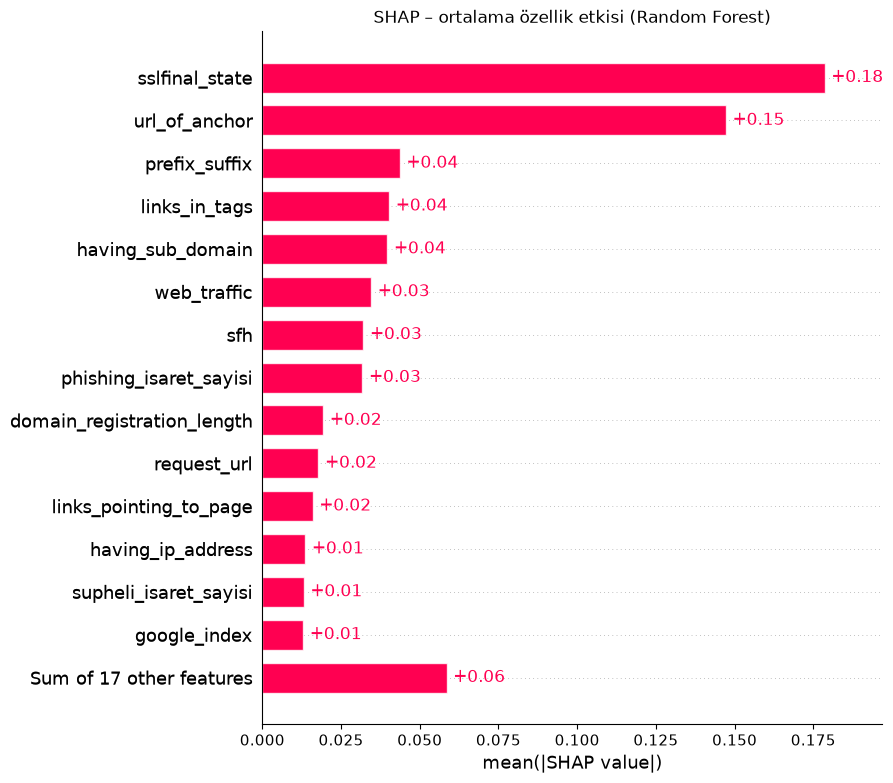

In [12]:
plt.figure()
shap.plots.bar(shap_degerleri, max_display=15, show=False)
plt.title(f"SHAP – ortalama özellik etkisi ({model_adlari[en_iyi_kod]})")
grafik_kaydet("shap_bar")
plt.show()

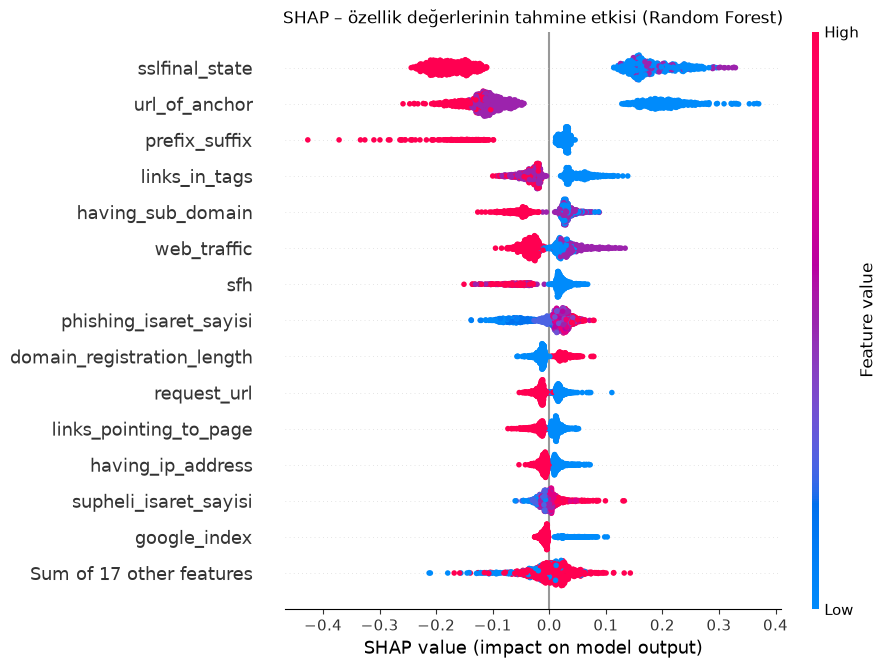

In [13]:
plt.figure()
shap.plots.beeswarm(shap_degerleri, max_display=15, show=False)
plt.title(f"SHAP – özellik değerlerinin tahmine etkisi ({model_adlari[en_iyi_kod]})")
grafik_kaydet("shap_beeswarm")
plt.show()

In [14]:
# Ortalama mutlak SHAP değerine göre özellik önemi
shap_onem = pd.DataFrame({
    "ozellik": X_test.columns,
    "ortalama_mutlak_shap": np.abs(shap_degerleri.values).mean(axis=0),
}).sort_values("ortalama_mutlak_shap", ascending=False).reset_index(drop=True)
shap_onem.to_csv("outputs/shap_onem.csv", index=False)
shap_onem.head(10)

,ozellik,ortalama_mutlak_shap
0,sslfinal_state,0.178607
1,url_of_anchor,0.147250
2,prefix_suffix,0.043666
3,links_in_tags,0.040288
4,having_sub_domain,0.039707
5,web_traffic,0.034561
6,sfh,0.032089
7,phishing_isaret_sayisi,0.031784
8,domain_registration_length,0.019337
9,request_url,0.017818


### 4.2 Yerel açıklama: tek bir sitenin tahmini

Waterfall grafiği, modelin ortalama tahmininden (alttaki değer) başlayarak her özelliğin tahmini ne kadar artırdığını (kırmızı, phishing yönü) veya azalttığını (mavi, normal yönü) gösterir. Bir doğru tespit edilmiş phishing sitesi ve bir kaçırılmış phishing sitesi incelenir.

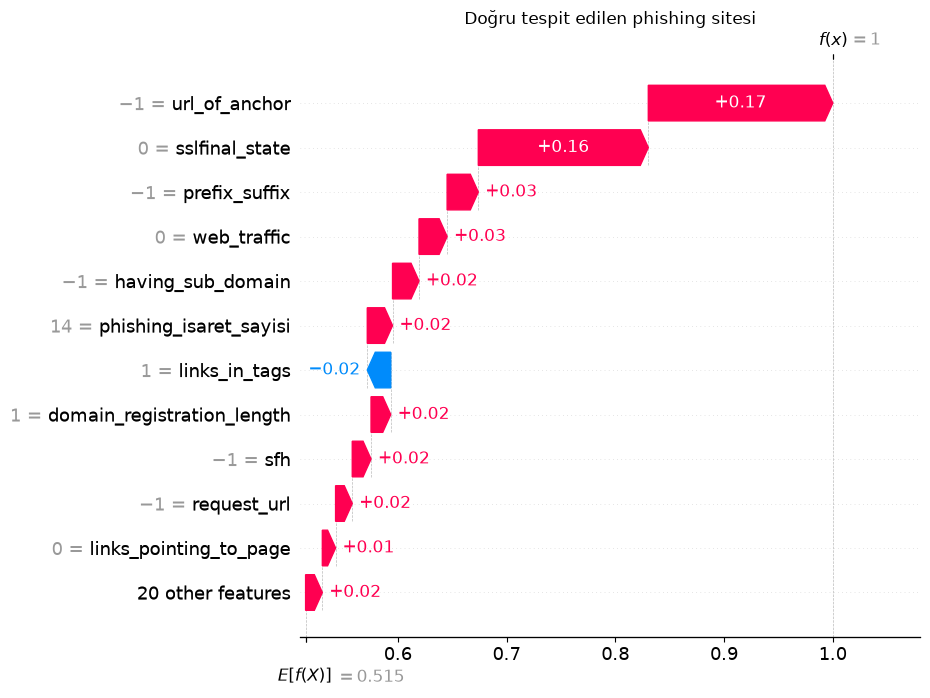

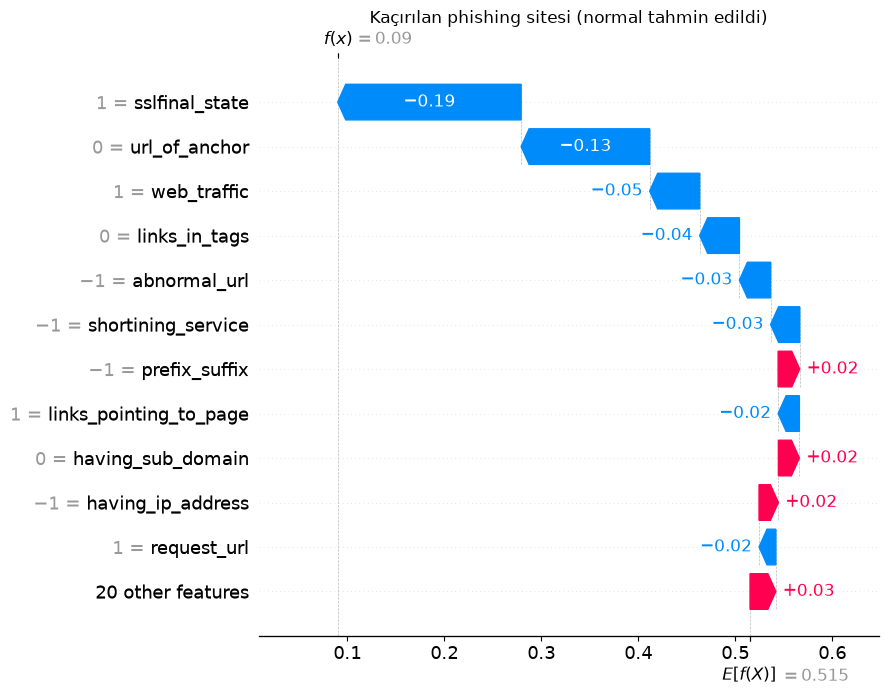

In [15]:
tahmin_sutunu = tahminler.loc[X_test.index, f"{en_iyi_kod}_tahmin"]
dogru_phishing = np.where((y_test == -1) & (tahmin_sutunu == -1))[0]
kacirilan = np.where((y_test == -1) & (tahmin_sutunu == 1))[0]

ornekler = [("dogru_tespit", dogru_phishing[0], "Doğru tespit edilen phishing sitesi")]
if len(kacirilan):
    ornekler.append(("kacirilan", kacirilan[0], "Kaçırılan phishing sitesi (normal tahmin edildi)"))

for dosya, i, baslik in ornekler:
    if i >= len(shap_degerleri.values):    # ağaç dışı modelde yalnızca 300 örnek açıklandı
        continue
    plt.figure()
    shap.plots.waterfall(shap_degerleri[i], max_display=12, show=False)
    plt.title(baslik)
    grafik_kaydet(f"shap_waterfall_{dosya}")
    plt.show()

## 5. Sonuçların karşılaştırılması

### 5.1 Karşılaştırma tablosu

In [16]:
tablo = test_sonuc.copy()
tablo.insert(1, "validation_f1", [en_iyi_param.loc[k, "val_f1"] for k in modeller])
tablo["egitim_suresi_sn"] = [en_iyi_param.loc[k, "fit_suresi_sn"] for k in modeller]
tablo["parametreler"] = [en_iyi_param.loc[k, "parametreler"] for k in modeller]
tablo = tablo.sort_values("f1", ascending=False).reset_index(drop=True)
tablo.to_csv("outputs/model_karsilastirma.csv", index=False)
tablo

,model,validation_f1,f1,recall,precision,accuracy,roc_auc,egitim_suresi_sn,parametreler
0,Random Forest,0.9610,0.9646,0.9630,0.9663,0.9636,0.9944,1.709,"{'max_depth': 20, 'max_features': 'log2', 'min..."
1,SVM,0.9548,0.9631,0.9647,0.9615,0.9619,0.9889,3.210,"{'model__C': 1, 'model__gamma': 0.1, 'model__k..."
2,XGBoost,0.9605,0.9589,0.9597,0.9581,0.9576,0.9941,0.567,"{'learning_rate': 0.3, 'max_depth': 5, 'n_esti..."
3,KNN,0.9494,0.9480,0.9496,0.9464,0.9463,0.9916,0.046,"{'model__metric': 'manhattan', 'model__n_neigh..."
4,Logistic Regression,0.9286,0.9350,0.9311,0.9390,0.9333,0.9780,0.123,"{'model__C': 0.1, 'model__penalty': 'l2'}"


`egitim_suresi_sn`: en iyi parametrelerle bir CV katında modelin ortalama eğitim süresi (saniye).

### 5.2 Performans grafikleri

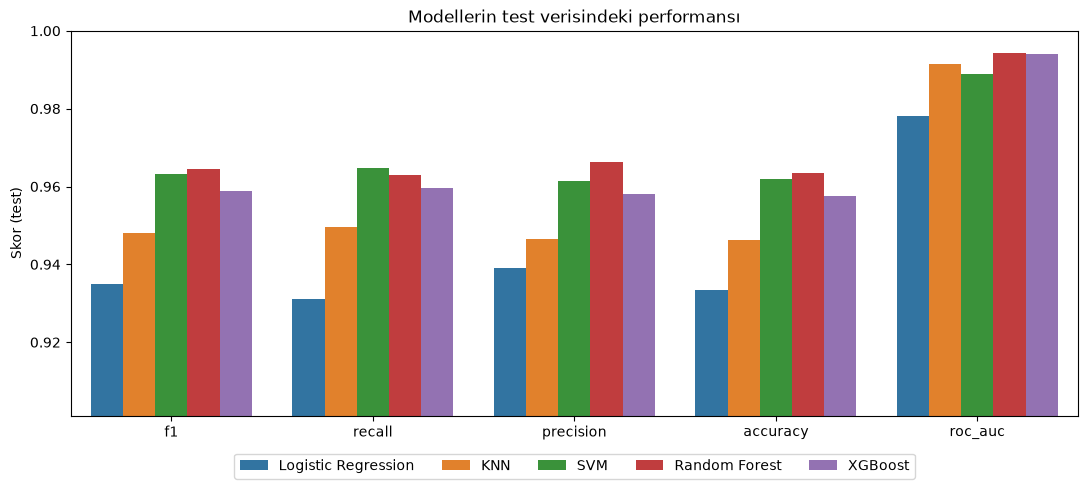

In [17]:
metrikler = test_sonuc.melt(id_vars="model", var_name="metrik", value_name="skor")

plt.figure(figsize=(13, 5))
ax = sns.barplot(data=metrikler, x="metrik", y="skor", hue="model")
ax.set_ylim(metrikler["skor"].min() - 0.03, 1.0)
ax.set_xlabel("")
ax.set_ylabel("Skor (test)")
ax.set_title("Modellerin test verisindeki performansı")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
grafik_kaydet("model_karsilastirma_metrikler")
plt.show()

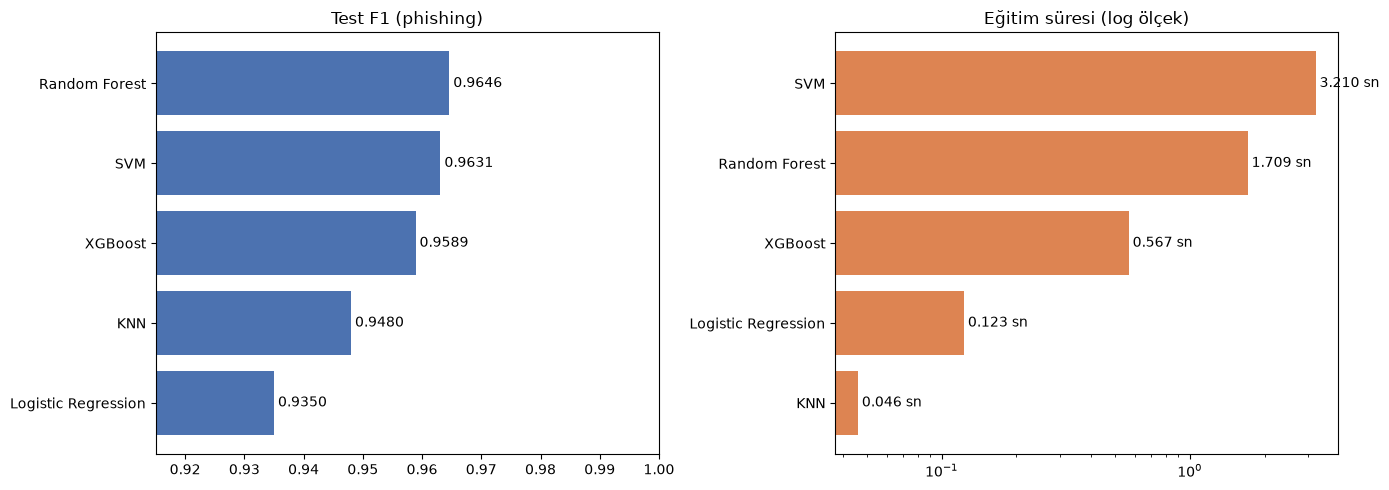

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sirali = tablo.sort_values("f1")
axes[0].barh(sirali["model"], sirali["f1"], color="#4c72b0")
for i, v in enumerate(sirali["f1"]):
    axes[0].text(v, i, f" {v:.4f}", va="center")
axes[0].set_xlim(sirali["f1"].min() - 0.02, 1)
axes[0].set_title("Test F1 (phishing)")

sirali = tablo.sort_values("egitim_suresi_sn")
axes[1].barh(sirali["model"], sirali["egitim_suresi_sn"], color="#dd8452")
for i, v in enumerate(sirali["egitim_suresi_sn"]):
    axes[1].text(v, i, f" {v:.3f} sn", va="center")
axes[1].set_xscale("log")      # süreler arasında büyük fark olduğu için logaritmik eksen
axes[1].set_title("Eğitim süresi (log ölçek)")

plt.tight_layout()
grafik_kaydet("model_karsilastirma_f1_sure")
plt.show()

### 5.3 Modellerin avantajları ve dezavantajları

| Model | Avantajlar | Dezavantajlar |
|---|---|---|
| **Logistic Regression** | Çok hızlı eğitilir ve tahmin yapar. Katsayıları doğrudan yorumlanabilir. Train ve validation skorları neredeyse aynı, overfitting yok. | Sınıfları yalnızca doğrusal bir sınırla ayırabilir, özellikler arası etkileşimleri yakalayamaz. Bu yüzden en düşük başarıyı verdi (underfitting). |
| **KNN** | Basit ve sezgisel, eğitim aşaması yok. Doğrusal olmayan sınırları yakalayabilir. | Tahmin sırasında tüm eğitim verisiyle mesafe hesapladığı için büyük veride yavaştır. Ölçeklemeye ve komşu sayısına duyarlıdır. `distance` ağırlığında eğitim verisini ezberler. |
| **SVM** | rbf çekirdeğiyle doğrusal olmayan sınırlar çizebilir. Marj maksimizasyonu sayesinde iyi genelleme yapar. | Eğitim süresi en uzun olan model, büyük veride yavaşlar. `C` ve `gamma`'ya çok duyarlıdır. Varsayılan ayarda olasılık üretmez ve yorumlanması zordur. |
| **Random Forest** | Yüksek başarı, az ayarla iyi sonuç verir. Bağımsız ağaçların oylaması sayesinde tek ağaca göre overfitting'e dayanıklıdır. Ölçekleme gerektirmez. | Derin ağaçlar eğitim verisini ezberleyebilir (train F1 ≈ 1). Çok sayıda ağaç olduğu için model büyüktür ve kararları doğrudan yorumlanamaz (SHAP gibi yöntemler gerekir). |
| **XGBoost** | Ağaçları sırayla, hataları düzelterek kurduğu için tablo verilerinde genellikle en başarılı yöntemlerdendir. Hızlıdır ve düzenlileştirme parametreleri içerir. | Ayarlanacak parametre sayısı fazladır ve parametrelere duyarlıdır. Yanlış ayarda overfitting'e yatkındır. Etiketlerin 0/1 olmasını gerektirir. |

## 6. Sonuç ve öneriler

### 6.1 Genel sonuç

In [19]:
# Sonuç bölümünde kullanılacak özet bilgiler
val_en_iyi = model_adlari[en_iyi_param["val_f1"].idxmax()]
test_en_iyi = test_sonuc.loc[test_sonuc["f1"].idxmax(), "model"]
print(f"Validation F1'e göre en iyi model : {val_en_iyi}")
print(f"Test F1'e göre en iyi model       : {test_en_iyi}")
print(f"Validation – test F1 farkı (ortalama mutlak): {karsilastirma['val_test_farki'].abs().mean():.4f}")
print(f"En etkili 5 özellik (SHAP): {', '.join(shap_onem['ozellik'].head(5))}")

Validation F1'e göre en iyi model : Random Forest
Test F1'e göre en iyi model       : Random Forest
Validation – test F1 farkı (ortalama mutlak): 0.0043
En etkili 5 özellik (SHAP): sslfinal_state, url_of_anchor, prefix_suffix, links_in_tags, having_sub_domain


- Phishing web sitesi tespiti için beş farklı algoritma ailesinden model (doğrusal, mesafe tabanlı, marj tabanlı, bagging ve boosting) karşılaştırılmıştır. Hiperparametreler 5 katlı cross-validation ile seçilmiş, modeller test verisinde bir kez değerlendirilmiştir.
- **En başarılı model Random Forest olmuştur.** Hem validation (F1 = 0,9610) hem test (F1 = 0,9646) verisinde ilk sıradadır. Phishing sitelerinin %96,3'ünü yakalamış, phishing dediği sitelerin %96,6'sı gerçekten phishing çıkmıştır.
- Test verisinde SVM (0,9631) ile XGBoost (0,9589) sıra değiştirmiştir. Validation'da XGBoost ikinci, SVM üçüncüdür. Bu üç model arasındaki farklar 0,006'nın altında olduğu için pratikte birbirine yakın başarıda kabul edilebilir. KNN (0,9480) ve Logistic Regression (0,9350) daha geride kalmıştır.
- Validation ve test F1 skorları arasındaki ortalama fark 0,004'tür. Bu, hiperparametre seçimi sırasında validation verisine aşırı uyum olmadığını ve modellerin daha önce görmedikleri veride de aynı başarıyı gösterdiğini gösterir. Random Forest ve KNN'de train F1'in 1,0 olması eğitim verisini tamamen ayırabildiklerini gösterir, ancak test skorlarının validation skorlarıyla tutarlı olması bunun genelleme başarısını düşürmediğini ortaya koyar.
- SHAP analizine göre model kararlarında en etkili özellikler SSL sertifikasının durumu (`sslfinal_state`) ve sayfadaki linklerin yönlendiği yer (`url_of_anchor`) olmuştur. Bu sonuç, 01'deki korelasyon analizi ve 02'deki feature importance sonuçlarıyla tutarlıdır. Türetilen `phishing_isaret_sayisi` özelliği de en etkili 10 özellik arasında yer almıştır.

### 6.2 Neden bazı modeller daha iyi performans gösterdi?

- **Özellikler arası etkileşim:** Phishing belirtileri tek başına değil, birlikte değerlendirildiğinde anlam kazanır (ör. SSL sertifikası güvenilir değil *ve* linkler başka domaine gidiyor). Ağaç modelleri bu tür "eğer–ise" kurallarını doğal olarak öğrenir. Logistic Regression ise her özelliğin etkisini ayrı ayrı topladığı için bu etkileşimleri yakalayamaz ve en düşük başarıyı vermiştir. Train ve validation skorlarının neredeyse aynı olması, bu modelin veriyi yeterince öğrenemediğini (underfitting) gösterir.
- **Doğrusal olmayan sınırlar:** SVM, rbf çekirdeği sayesinde sınıflar arasında eğri sınırlar çizebildiği için Logistic Regression'dan belirgin şekilde iyidir ve test verisinde ağaç modelleriyle aynı seviyeye ulaşmıştır. Ancak eğitim süresi en uzun olan modeldir.
- **Kategorik veri yapısı:** Özellikler -1/0/1 gibi az sayıda değer alır. Ağaçlar bu değerlere göre doğrudan bölünme yapabilir. Mesafe tabanlı KNN'de ise birçok site aynı noktaya düştüğünden mesafeler daha az ayırt edici olur.
- **Topluluk etkisi:** Random Forest bağımsız ağaçların oylamasıyla tek bir ağacın ezberleme eğilimini dengeler, XGBoost ise ağaçları sırayla hataları düzelterek kurar. İki yöntem de tek bir modele göre daha kararlı tahminler üretir. Bu veri setinde Random Forest'ın biraz daha başarılı olması, varsayılan davranışının bu boyuttaki bir veriye iyi uyması ve XGBoost'un daha fazla parametreye duyarlı olmasıyla açıklanabilir.

### 6.3 Öneriler

- **Model seçimi:** Hem validation hem test verisinde en iyi sonucu veren **Random Forest** önerilen modeldir. Daha hızlı eğitim gereken durumlarda XGBoost, eğitim süresi yaklaşık üç kat daha kısa olduğu için iyi bir alternatiftir (0,57 sn'ye karşı 1,71 sn).
- **Karar eşiği:** Phishing sitesini kaçırmak yanlış alarmdan daha maliyetli olduğu için, karar eşiği düşürülerek recall artırılabilir (bazı normal sitelerin uyarı alması pahasına).
- **Veri seti:** Veri seti 2015 yılına aittir ve özellikler önceden kodlanmıştır. Güncel phishing teknikleri için yeni ve ham verilerle (ör. URL metninin kendisi) model güncellenmelidir.
- **Tekrarlanan kayıtlar:** Veri setinin %47'si tekrarlanan kayıtlardan oluşuyordu. Temizlenmeden yapılan değerlendirmeler test başarısını olduğundan yüksek gösterebilir. Benzer veri setlerinde bu kontrol mutlaka yapılmalıdır.